# 01 · Data ingestion: four free data streams

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/01_data_ingestion.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAANS fuses four open sources into one hourly picture of each city:

| Source | What it tells us | Downloader |
|---|---|---|
| Open-Meteo (ERA5 reanalysis) | Hourly wind, humidity, temperature and boundary layer height | `saans/ingest/weather.py` |
| OpenAQ v3 | Hourly PM2.5 from reference monitors and low-cost sensors | `saans/ingest/openaq.py` |
| NASA FIRMS | Every satellite-detected fire over the Punjab-Haryana burning belt and Sindh | `saans/ingest/firms.py` |
| GDELT news index | Smog headlines that the LLM turns into an event calendar (notebook 05) | `saans/ingest/news.py` |

The downloaders are plain Python modules, run once from the command line (`python -m saans.ingest.weather` etc.). They save every API response untouched in `data/raw/`, then parse it into tidy tables in `data/interim/`. This notebook loads those tables and checks **what actually arrived**, before any cleaning.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from saans.config import CITIES, INTERIM, REPORTS, LOCAL_TZ
from saans import viz

viz.use_style()
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

# Set to True to re-run every download (needs API keys; about 2 hours, mostly NASA FIRMS)
REDOWNLOAD = False
if REDOWNLOAD:
    from saans.ingest import firms, news, openaq, weather
    weather.main(); openaq.coverage(); openaq.hours(); firms.main([]); news.main()

## 1. Weather: Open-Meteo historical API (ERA5)

13 hourly variables for each city, 1 Jan 2020 to 31 Jan 2026, stored in UTC. ERA5 is a weather model re-run over the past and corrected with observations, on a ~25 km grid, so it has (almost) no gaps.

In [3]:
wx = pd.read_parquet(INTERIM / "weather_hourly.parquet")
print(f"{len(wx):,} hourly rows x {wx.shape[1] - 2} variables")
wx.head()

266,760 hourly rows x 13 variables


,city,time_utc,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,wind_speed_100m,wind_direction_100m,shortwave_radiation,boundary_layer_height
0,faisalabad,2020-01-01 00:00:00+00:00,2.4,97,2.0,0.0,998.5,95,1.82,9,2.9,4.62,18,0.0,35.0
1,faisalabad,2020-01-01 01:00:00+00:00,2.2,97,1.8,0.0,998.5,95,1.66,25,3.0,4.65,28,0.0,30.0
2,faisalabad,2020-01-01 02:00:00+00:00,1.5,98,1.2,0.0,998.7,95,2.10,25,2.9,4.16,35,0.0,20.0
3,faisalabad,2020-01-01 03:00:00+00:00,3.3,95,2.6,0.0,999.6,96,1.89,32,2.9,3.89,42,30.0,30.0
4,faisalabad,2020-01-01 04:00:00+00:00,5.7,89,4.0,0.0,1000.4,95,1.63,47,4.0,3.52,55,148.0,50.0


In [4]:
summary = wx.groupby("city").agg(rows=("time_utc", "size"), first=("time_utc", "min"), last=("time_utc", "max"))
summary["missing_cells"] = wx.drop(columns="time_utc").groupby("city").apply(lambda g: int(g.isna().sum().sum()))
summary

,rows,first,last,missing_cells
city,,,,
faisalabad,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
islamabad,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
karachi,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
lahore,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
multan,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368


Every city has every expected hour, but each shows exactly **4,368 missing cells** (182 days x 24 hours), too round to be random:

In [5]:
na = wx[wx.boundary_layer_height.isna()]
print("Variable(s) with gaps:", [c for c in wx.columns if wx[c].isna().any()])
print("Gap:", na.time_utc.min(), "to", na.time_utc.max(), "| identical in all cities:", na.groupby("city").size().nunique() == 1)

Variable(s) with gaps: ['boundary_layer_height']
Gap: 2024-01-01 00:00:00+00:00 to 2024-06-30 23:00:00+00:00 | identical in all cities: True


Boundary layer height is missing from Jan to Jun 2024. The same hole appears in every model Open-Meteo serves (checked: `best_match`, `era5`, `era5_seamless`, `ecmwf_ifs`), so it is a gap in the provider's archive. It is logged as finding **W1** and fixed in notebook 02 by imputation.

Why boundary layer height matters: it is the height of the "lid" that traps pollution near the ground. On winter nights it collapses.

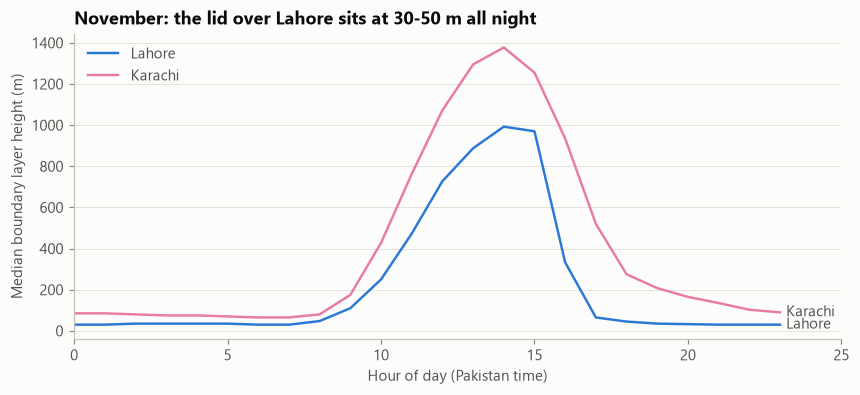

In [6]:
wx["time_pkt"] = wx.time_utc.dt.tz_convert(LOCAL_TZ)
nov = wx[wx.time_pkt.dt.month == 11]
fig, ax = plt.subplots(figsize=(9, 3.6))
for city in ["lahore", "karachi"]:
    s = nov[nov.city == city].groupby(nov.time_pkt.dt.hour).boundary_layer_height.median()
    ax.plot(s.index, s.values, color=viz.CITY_COLORS[city], label=CITIES[city].name)
    ax.annotate(CITIES[city].name, (23, s.values[-1]), xytext=(4, 0), textcoords="offset points",
                color=viz.INK_2, va="center")
ax.set(title="November: the lid over Lahore sits at 30-50 m all night",
       xlabel="Hour of day (Pakistan time)", ylabel="Median boundary layer height (m)", xlim=(0, 25))
ax.legend(loc="upper left")
fig.savefig(REPORTS / "figures/blh_diurnal_november.png", bbox_inches="tight")
plt.show()

## 2. Air quality: OpenAQ v3

The first question was coverage: how many PM2.5 sensors exist within 25 km of each city, and over which years? This was the project's first risk check.

In [7]:
sensors = pd.read_csv(INTERIM / "openaq_sensors.csv", parse_dates=["first_utc", "last_utc"])
pm = sensors[(sensors.parameter == "pm25") & (sensors.days_in_period > 0)].copy()
pm["kind"] = pm.is_monitor.map({True: "reference monitor", False: "low-cost sensor"})
pm.groupby(["city", "kind"]).agg(sensors=("sensor_id", "size"), providers=("provider", lambda s: ", ".join(sorted(set(s)))),
                                 first=("first_utc", "min"), last=("last_utc", "max"))

sensors                       providers                     first                      last
city       kind                                                                                                          
faisalabad low-cost sensor         36           AirGradient, Hawanama 2025-06-23 06:00:00+00:00 2026-10-24 07:00:00+00:00
islamabad  low-cost sensor         34           AirGradient, Hawanama 2025-05-06 07:00:00+00:00 2026-10-24 07:00:00+00:00
           reference monitor        2      AirNow, StateAir Islamabad 2019-05-22 22:00:00+00:00 2026-02-16 13:00:00+00:00
karachi    low-cost sensor         37  AirGradient, Clarity, Hawanama 2023-11-28 16:58:32+00:00 2026-10-24 07:00:00+00:00
           reference monitor        1                          AirNow 2019-05-22 22:00:00+00:00 2025-03-04 12:00:00+00:00
lahore     low-cost sensor         73  AirGradient, Clarity, Hawanama 2023-11-28 16:58:05+00:00 2026-10-24 07:00:00+00:00
           reference monitor        1                 StateAir Lahore 2019-05-22 22:00:00+00:00 2025-03-04 12:00:00+00:00
multan     low-cost sensor         16           AirGradient, Hawanama 2025-06-16 06:00:00+00:00 2026-10-24 07:00:00+00:00

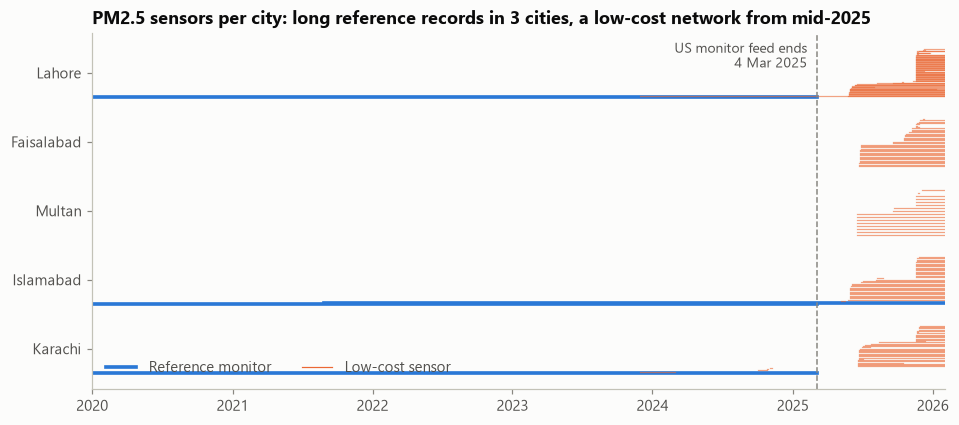

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = ["karachi", "islamabad", "multan", "faisalabad", "lahore"]
for i, city in enumerate(order):
    g = pm[pm.city == city].sort_values("first_utc")
    for j, s in enumerate(g.itertuples()):
        y = i + (j / max(len(g), 1)) * 0.7 - 0.35
        ref = s.is_monitor
        ax.plot([s.first_utc, min(s.last_utc, pd.Timestamp("2026-01-31", tz="UTC"))], [y, y],
                color=viz.SERIES[0] if ref else viz.SERIES[1], lw=2.4 if ref else 0.8, alpha=1 if ref else 0.6)
ax.set_yticks(range(len(order)), [CITIES[c].name for c in order])
ax.axvline(pd.Timestamp("2025-03-04", tz="UTC"), color=viz.MUTED, ls="--", lw=1)
ax.annotate("US monitor feed ends\n4 Mar 2025", (pd.Timestamp("2025-03-04", tz="UTC"), 4.45), xytext=(-6, 0),
            textcoords="offset points", ha="right", va="top", color=viz.INK_2, fontsize=9)
ax.plot([], [], color=viz.SERIES[0], lw=2.4, label="Reference monitor")
ax.plot([], [], color=viz.SERIES[1], lw=0.8, label="Low-cost sensor")
ax.set(title="PM2.5 sensors per city: long reference records in 3 cities, a low-cost network from mid-2025",
       xlim=(pd.Timestamp("2020-01-01", tz="UTC"), pd.Timestamp("2026-02-01", tz="UTC")))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", ncol=2)
fig.savefig(REPORTS / "figures/sensor_coverage.png", bbox_inches="tight")
plt.show()

What the coverage check shows, and how the design responds:

* **Lahore, Islamabad and Karachi** have reference monitors at the US diplomatic posts from 2019. That feed **stopped on 4 March 2025**. Lahore also has a Clarity monitor from Nov 2023 and Islamabad a second AirNow feed until Feb 2026.
* **Faisalabad and Multan** have no history before mid-2025: only AirGradient low-cost sensors, installed in June 2025.
* So the model trains on Lahore, Islamabad and Karachi (2020 to Sep 2024), is tested on the 2024 season, and is then tested on **Faisalabad and Multan in the 2025 season, cities it has never seen**. That is a stricter test than the proposal planned.

Next, the hourly values themselves:

In [9]:
aq = pd.read_parquet(INTERIM / "openaq_hourly.parquet")
print(f"{len(aq):,} hourly PM2.5 records from {aq.sensor_id.nunique()} sensors")
aq.groupby("city").agg(records=("value", "size"), sensors=("sensor_id", "nunique"),
                       first=("time_utc", "min"), last=("time_utc", "max"), median_ug_m3=("value", "median"))

587,969 hourly PM2.5 records from 200 sensors


,records,sensors,first,last,median_ug_m3
city,,,,,
faisalabad,94774,36,2025-06-23 05:00:00+00:00,2026-01-31 22:00:00+00:00,133.0
islamabad,153135,36,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,47.9
karachi,118133,38,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,35.8
lahore,188589,74,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,107.0
multan,33338,16,2025-06-16 05:00:00+00:00,2026-01-31 22:00:00+00:00,99.0


## 3. Fires: NASA FIRMS

Every fire pixel detected by two satellite instruments over the box 66-78 E, 24-34 N (Pakistani and Indian Punjab, Haryana, and Sindh down to Karachi):

* **VIIRS on Suomi-NPP**: 375 m pixels, passes at about 01:30 and 13:30 local time
* **MODIS on Terra and Aqua**: 1 km pixels, passes at about 10:30 and 13:30

NASA stores the time as an `HHMM` integer in UTC (`845` means 08:45). The downloader parses it into a proper UTC timestamp:

In [10]:
fires = pd.read_parquet(INTERIM / "firms_fires.parquet")
print(f"{len(fires):,} fire detections")
fires[["acq_date", "acq_time", "time_utc", "latitude", "longitude", "frp", "confidence", "source", "type"]].head()

1,184,817 fire detections


,acq_date,acq_time,time_utc,latitude,longitude,frp,confidence,source,type
0,2020-01-01,534,2020-01-01 05:34:00+00:00,33.18270,74.07740,12.30,48,MODIS_SP,0
1,2020-01-01,537,2020-01-01 05:37:00+00:00,25.26750,75.69580,6.20,57,MODIS_SP,0
2,2020-01-01,537,2020-01-01 05:37:00+00:00,25.26610,75.70610,13.40,76,MODIS_SP,0
3,2020-01-01,838,2020-01-01 08:38:00+00:00,26.94843,67.83544,5.03,n,VIIRS_SNPP_SP,0
4,2020-01-01,838,2020-01-01 08:38:00+00:00,25.10702,67.10941,3.78,n,VIIRS_SNPP_SP,0


C:\Users\Laptronics.co\AppData\Local\Temp\ipykernel_13696\2937792272.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly = fires.groupby([fires.time_utc.dt.to_period("M"), "source"]).size().unstack().fillna(0)


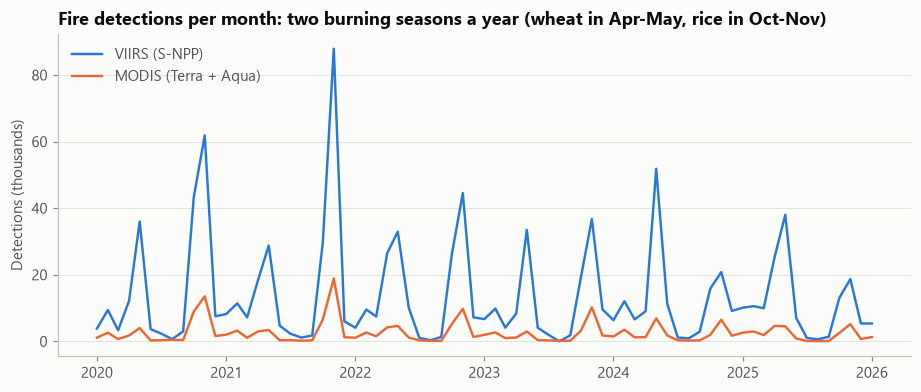

In [11]:
monthly = fires.groupby([fires.time_utc.dt.to_period("M"), "source"]).size().unstack().fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.8))
names = {"VIIRS_SNPP_SP": "VIIRS (S-NPP)", "MODIS_SP": "MODIS (Terra + Aqua)"}
for k, src in enumerate(["VIIRS_SNPP_SP", "MODIS_SP"]):
    if src in monthly:
        ax.plot(monthly.index.to_timestamp(), monthly[src] / 1000, color=viz.SERIES[k], label=names[src])
ax.set(title="Fire detections per month: two burning seasons a year (wheat in Apr-May, rice in Oct-Nov)",
       ylabel="Detections (thousands)")
ax.legend(loc="upper left")
fig.savefig(REPORTS / "figures/fires_per_month.png", bbox_inches="tight")
plt.show()

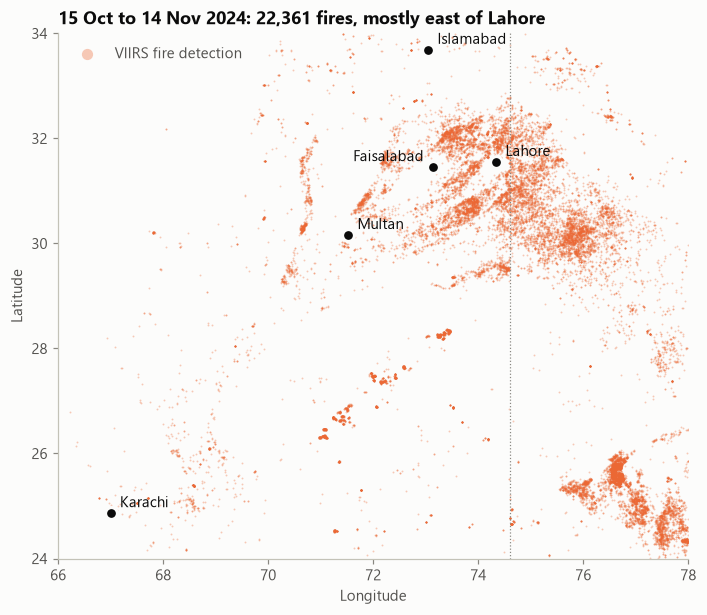

In [12]:
nov24 = fires[(fires.time_utc >= "2024-10-15") & (fires.time_utc < "2024-11-15") & (fires.source == "VIIRS_SNPP_SP")]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.scatter(nov24.longitude, nov24.latitude, s=1.5, color=viz.SERIES[1], alpha=0.35, linewidths=0, label="VIIRS fire detection")
for c in CITIES.values():
    ax.scatter(c.lon, c.lat, s=60, color=viz.INK, zorder=3, edgecolor=viz.SURFACE, linewidth=2)
    left = c.slug == "faisalabad"  # Faisalabad sits just west of Lahore: label it on the left so the names don't collide
    ax.annotate(c.name, (c.lon, c.lat), xytext=(-6 if left else 6, 4), textcoords="offset points", fontsize=10,
                color=viz.INK, ha="right" if left else "left")
ax.axvline(74.6, color=viz.MUTED, lw=0.8, ls=":")  # rough line of the India-Pakistan border near Lahore
ax.set(title=f"15 Oct to 14 Nov 2024: {len(nov24):,} fires, mostly east of Lahore", xlabel="Longitude", ylabel="Latitude",
       xlim=(66, 78), ylim=(24, 34))
ax.set_aspect("equal")
ax.grid(visible=False)
ax.legend(loc="upper left", markerscale=6)
fig.savefig(REPORTS / "figures/fires_map_nov2024.png", bbox_inches="tight")
plt.show()

The dotted line is a rough marker of the border east of Lahore. Most of the rice-stubble fires burn in Indian Punjab and Haryana, upwind of Lahore when the wind blows from the east-southeast, which is what the Upwind Fire Exposure Index in notebook 03 measures.

## 4. News headlines: GDELT

GDELT indexes online news worldwide. For every month of every smog season (October to January) the downloader pulled Pakistani articles that mention smog or AQI in the study cities. Only the headline, outlet, link and date are kept; notebook 05 turns them into structured events.

In [13]:
news = pd.read_csv(INTERIM / "news_headlines.csv", parse_dates=["time_utc"])
print(f"{len(news):,} unique headlines from {news.domain.nunique()} outlets")
news.sample(8, random_state=1)[["time_utc", "domain", "title"]].sort_values("time_utc")

2,255 unique headlines from 42 outlets


,time_utc,domain,title
6,2020-01-02 19:00:00+00:00,dailytimes.com.pk,2019 : a year in review | Daily times
579,2021-12-15 07:45:00+00:00,samaa.tv,Lahore suffers worst smog in four years
627,2021-12-20 05:15:00+00:00,tribune.com.pk,Effective government regulations can solve s...
679,2021-12-30 06:00:00+00:00,arynews.tv,Lahore once again ranks world most polluted city
1558,2024-11-06 15:15:00+00:00,samaa.tv,Big breaking : Mask - wearing made mandatory
1928,2025-10-05 01:00:00+00:00,tribune.com.pk,Lahore tops pollution index
2045,2025-10-31 18:15:00+00:00,tribune.com.pk,Suthra Punjab worsens air quality
2080,2025-11-06 03:30:00+00:00,thenews.com.pk,Politics of optics


## 5. Raw records received

These counts are the "rows received" column of the Data Quality Report. Cleaning starts from here.

In [14]:
raw_counts = pd.DataFrame([
    ("Open-Meteo weather (hourly rows)", len(wx)),
    ("OpenAQ PM2.5 (sensor-hours)", len(aq)),
    ("NASA FIRMS fire detections", len(fires)),
    ("GDELT news headlines", len(news)),
], columns=["source", "raw_records"])
raw_counts.loc[len(raw_counts)] = ["Total", raw_counts.raw_records.sum()]
raw_counts.to_csv(REPORTS / "raw_record_counts.csv", index=False)
raw_counts.style.format({"raw_records": "{:,}"}).hide(axis="index")

source,raw_records
Open-Meteo weather (hourly rows),"266,760"
OpenAQ PM2.5 (sensor-hours),"587,969"
NASA FIRMS fire detections,"1,184,817"
GDELT news headlines,"2,255"
Total,"2,041,801"
